EDA   ---- Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/processed/train_clean.csv')

In [6]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["day_name"] = df["date"].dt.day_name()
df["quarter"] = df["date"].dt.quarter
df["week"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [7]:
print(df["sales"].describe())

print("Mean:", df["sales"].mean())
print("Median:", df["sales"].median())
print("Standard Deviation:", df["sales"].std())
print("Skewness:", df["sales"].skew())

count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64
Mean: 52.250286966046005
Median: 47.0
Standard Deviation: 28.801143603517097
Skewness: 0.8671122960235801


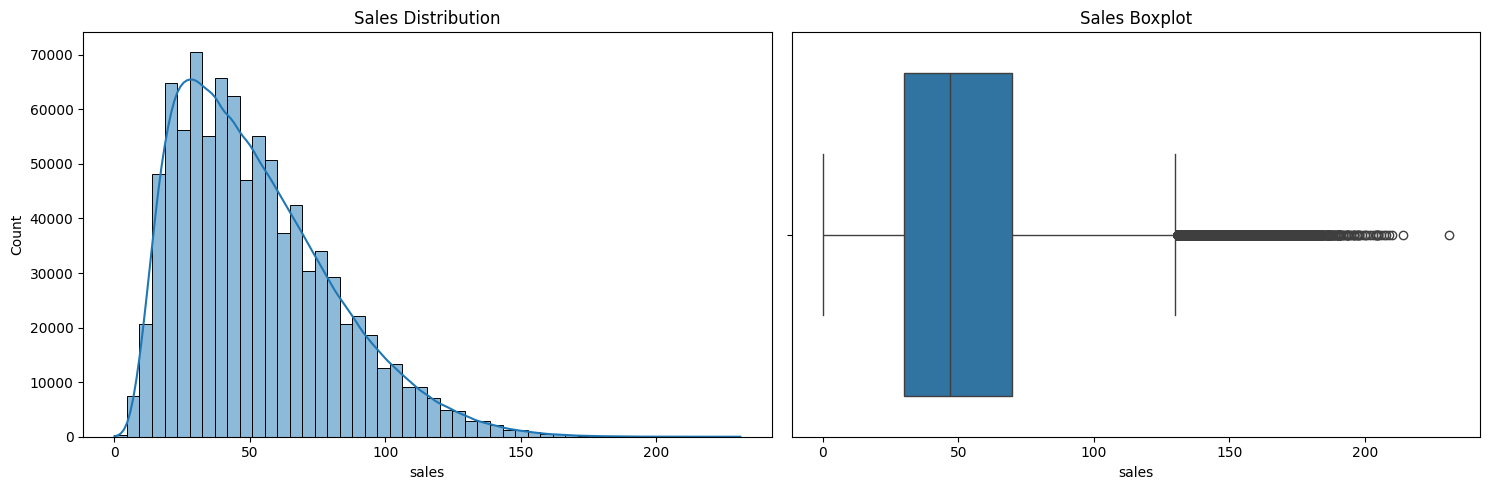

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(
    df["sales"],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Sales Distribution")
sns.boxplot(
    x=df["sales"],
    ax=axes[1]
)

axes[1].set_title("Sales Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
daily_sales = df.groupby(
    "date",
    as_index=False
)["sales"].sum()

daily_sales.head()

,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


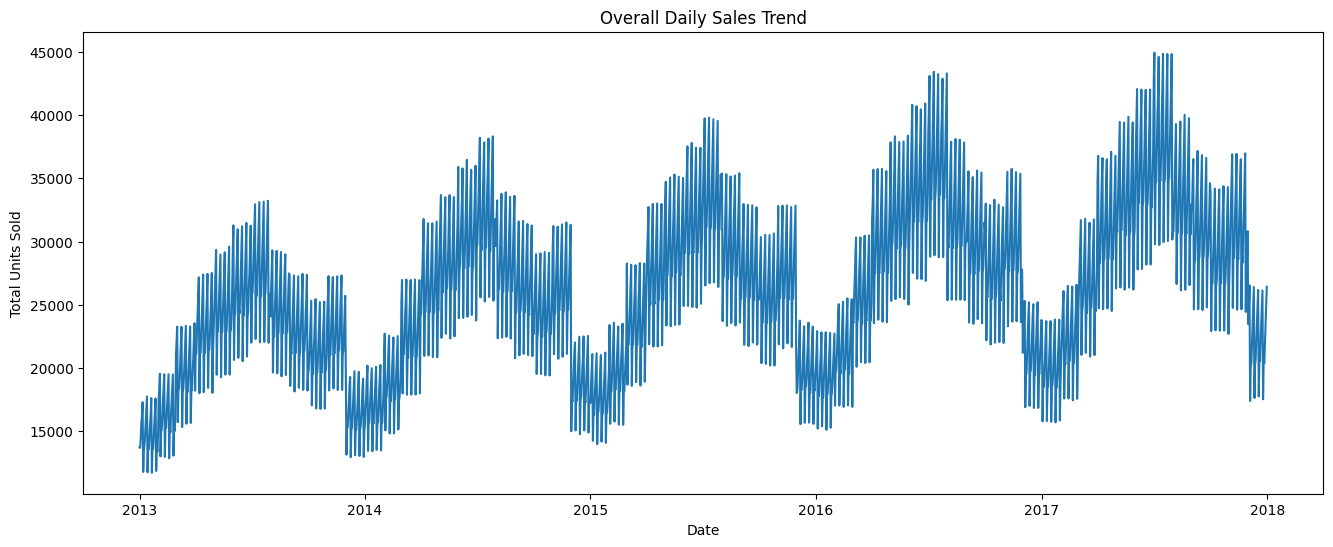

In [10]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Overall Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.show()

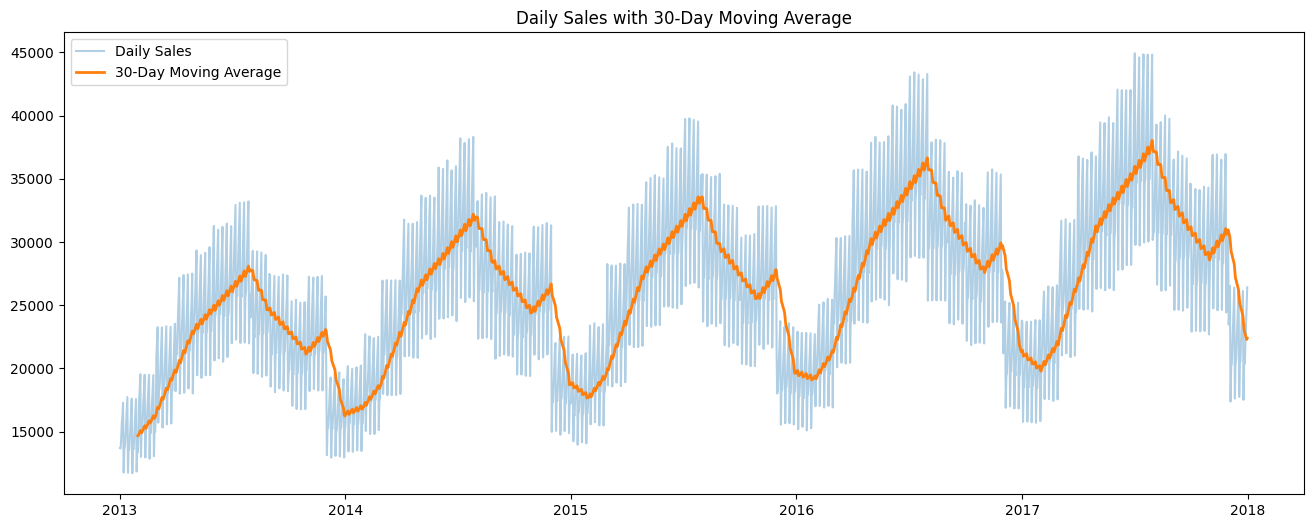

In [11]:
daily_sales["rolling_mean"] = (
    daily_sales["sales"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    daily_sales["date"],
    daily_sales["rolling_mean"],
    linewidth=2,
    label="30-Day Moving Average"
)

plt.title("Daily Sales with 30-Day Moving Average")
plt.legend()
plt.show()

In [14]:
weekly_sales = df.groupby(
    "day_name"
)["sales"].mean()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_sales = weekly_sales.reindex(day_order)

print(weekly_sales)

day_name
Monday       41.429638
Tuesday      48.225908
Wednesday    48.368506
Thursday     51.723218
Friday       55.157249
Saturday     58.662697
Sunday       62.143333
Name: sales, dtype: float64


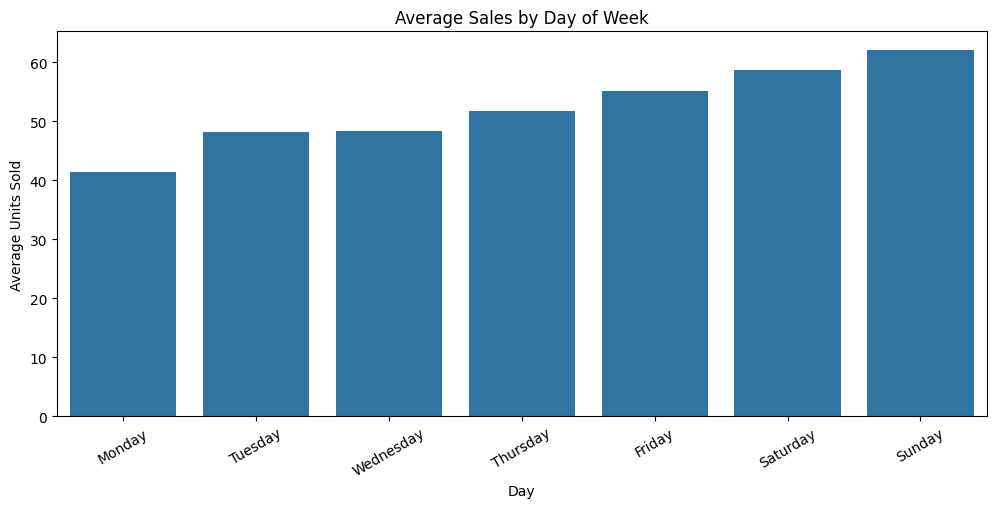

In [15]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=weekly_sales.index,
    y=weekly_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=30)
plt.show()

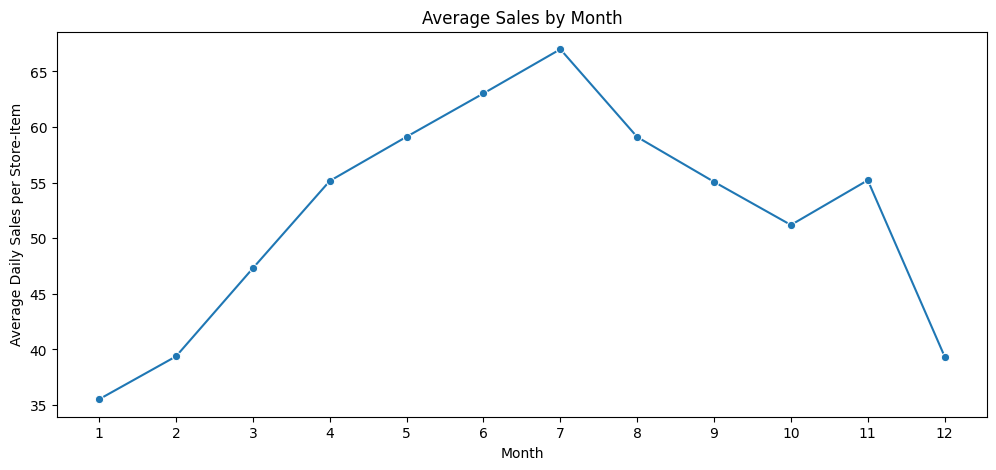

In [16]:
monthly_sales = df.groupby(
    "month"
)["sales"].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales per Store-Item")

plt.xticks(range(1, 13))
plt.show()

year
2013    43.513660
2014    50.057436
2015    52.256915
2016    56.596503
2017    58.815014
Name: sales, dtype: float64


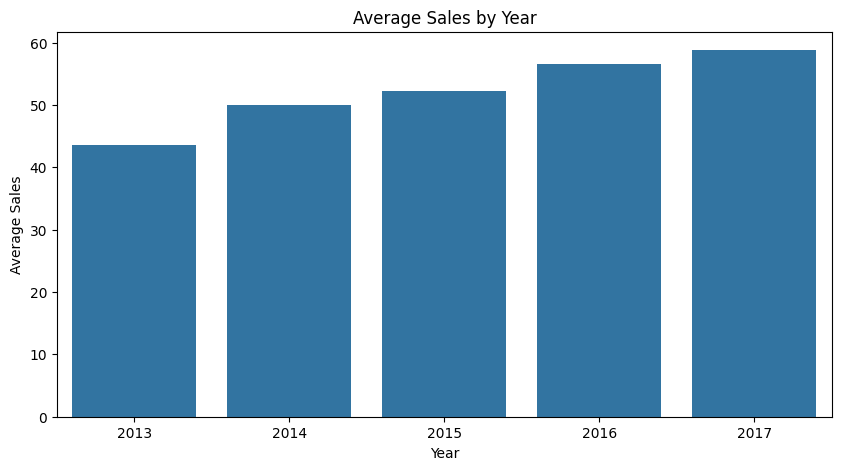

In [17]:
yearly_sales = df.groupby(
    "year"
)["sales"].mean()

print(yearly_sales)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=yearly_sales.index,
    y=yearly_sales.values
)

plt.title("Average Sales by Year")
plt.xlabel("Year")
plt.ylabel("Average Sales")

plt.show()

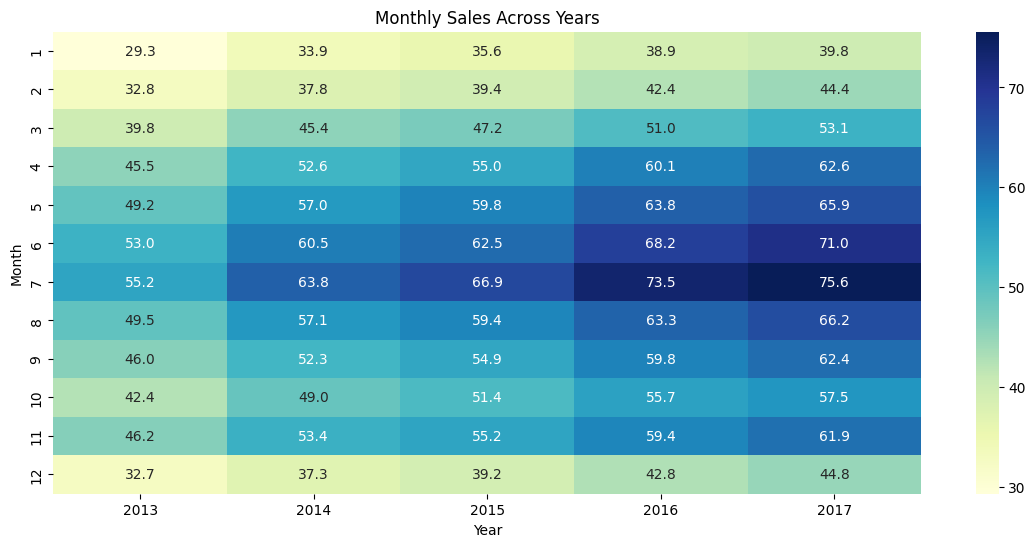

In [18]:
monthly_yearly = df.pivot_table(
    index="month",
    columns="year",
    values="sales",
    aggfunc="mean"
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    monthly_yearly,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Monthly Sales Across Years")
plt.xlabel("Year")
plt.ylabel("Month")

plt.show()

In [19]:
product_sales = df.groupby(
    "item"
)["sales"].agg(
    ["sum", "mean", "median", "std"]
).reset_index()

product_sales.columns = [
    "item",
    "total_sales",
    "average_sales",
    "median_sales",
    "sales_std"
]

product_sales = product_sales.sort_values(
    "total_sales",
    ascending=False
)

print(product_sales.head(10))

    item  total_sales  average_sales  median_sales  sales_std
14    15      1607442      88.030778          85.0  29.522852
27    28      1604713      87.881325          85.0  29.501781
12    13      1539621      84.316594          81.0  28.311031
17    18      1538876      84.275794          81.0  28.430621
24    25      1473334      80.686418          78.0  27.238817
44    45      1471467      80.584173          78.0  27.318402
37    38      1470330      80.521906          77.0  27.141799
21    22      1469971      80.502245          78.0  27.118163
35    36      1406548      77.028916          74.0  26.067440
7      8      1405108      76.950055          74.0  26.130697


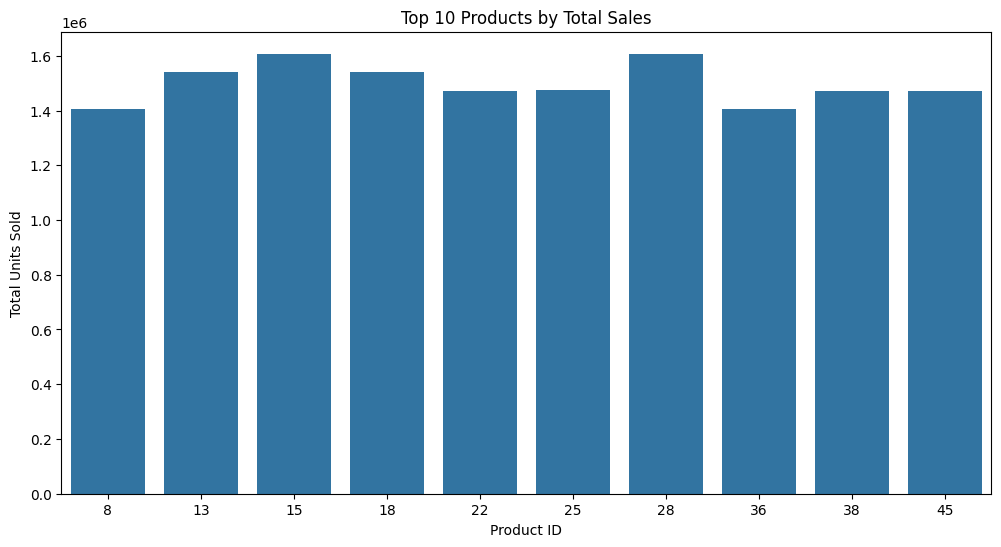

In [20]:
top_products = product_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="item",
    y="total_sales"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")

plt.show()

In [21]:
store_sales = df.groupby(
    "store"
)["sales"].agg(
    ["sum", "mean", "std"]
).reset_index()

store_sales.columns = [
    "store",
    "total_sales",
    "average_sales",
    "sales_std"
]

store_sales = store_sales.sort_values(
    "total_sales",
    ascending=False
)

print(store_sales)

   store  total_sales  average_sales  sales_std
1      2      6120128      67.033165  33.595810
7      8      5856169      64.142048  32.231751
2      3      5435144      59.530602  29.974102
9     10      5360158      58.709288  29.554994
8      9      5025976      55.049025  27.832186
3      4      5012639      54.902946  27.733097
0      1      4315603      47.268379  24.006252
4      5      3631016      39.770164  20.365757
5      6      3627670      39.733516  20.310451
6      7      3320009      36.363735  18.684825


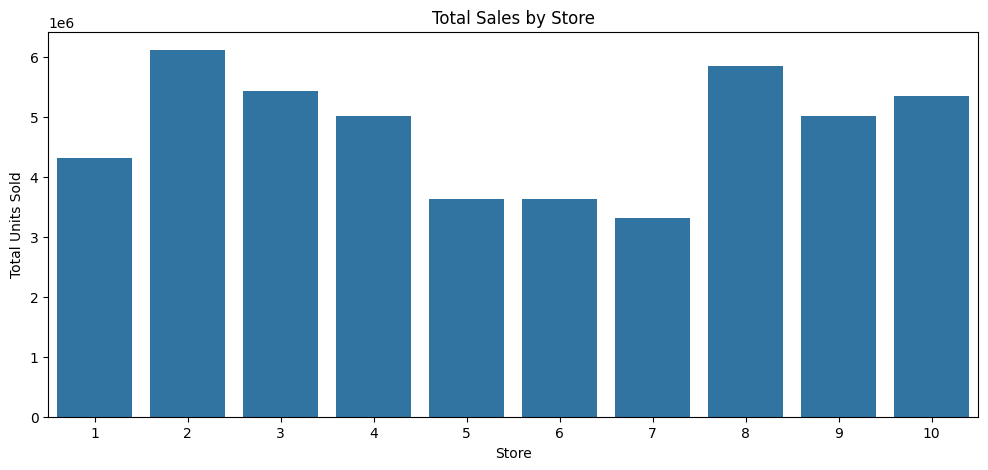

In [22]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=store_sales,
    x="store",
    y="total_sales"
)

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Units Sold")

plt.show()

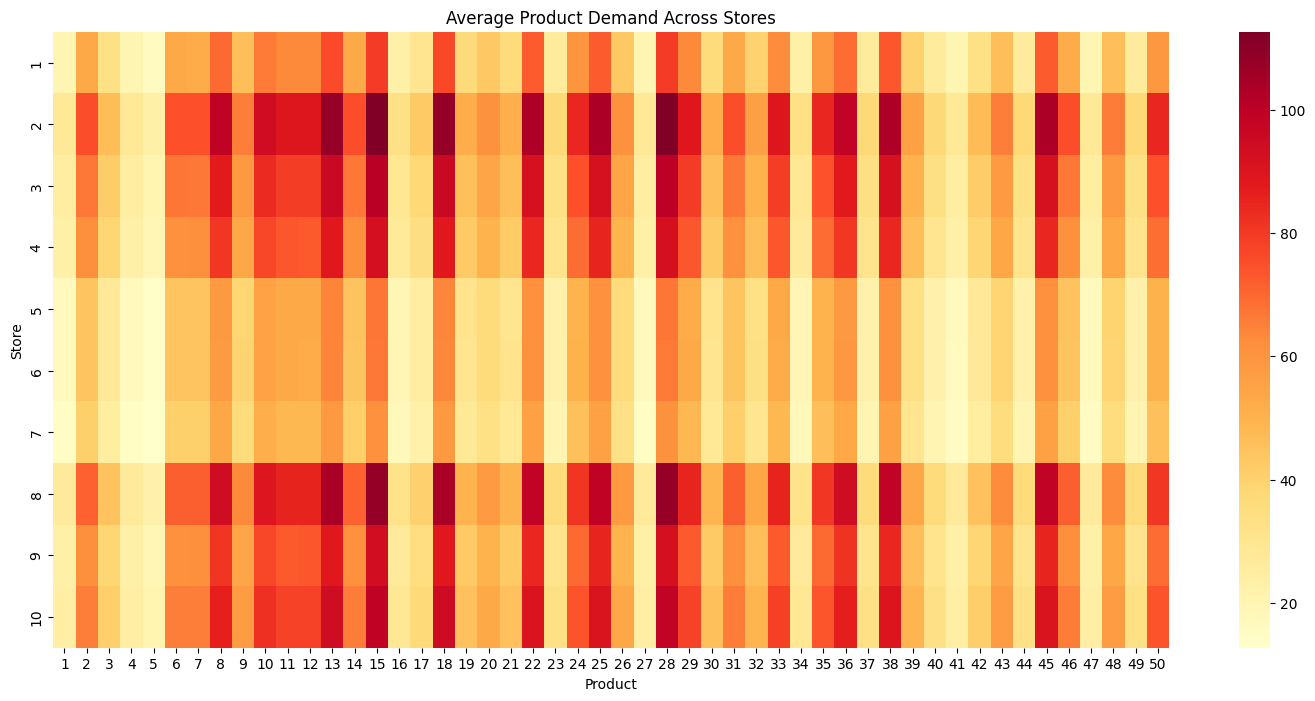

In [23]:
store_item_matrix = df.pivot_table(
    index="store",
    columns="item",
    values="sales",
    aggfunc="mean"
)

plt.figure(figsize=(18, 8))

sns.heatmap(
    store_item_matrix,
    cmap="YlOrRd"
)

plt.title("Average Product Demand Across Stores")
plt.xlabel("Product")
plt.ylabel("Store")

plt.show()

In [24]:
weekend_analysis = df.groupby(
    "is_weekend"
)["sales"].agg(
    ["mean", "median", "std", "count"]
)

print(weekend_analysis)

                 mean  median        std   count
is_weekend                                      
0           48.986695    44.0  26.680115  652000
1           60.403015    55.0  32.099892  261000


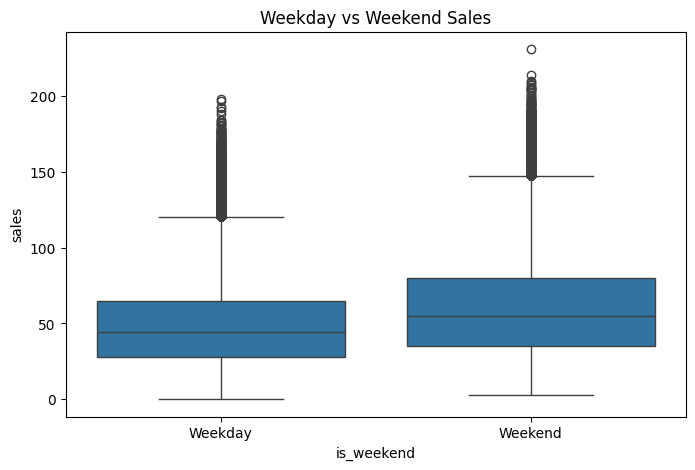

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_weekend",
    y="sales"
)

plt.xticks(
    [0, 1],
    ["Weekday", "Weekend"]
)

plt.title("Weekday vs Weekend Sales")

plt.show()

In [26]:
product_volatility = df.groupby(
    "item"
)["sales"].agg(
    ["mean", "std"]
)

product_volatility["cv"] = (
    product_volatility["std"] /
    product_volatility["mean"]
)

print(
    product_volatility.sort_values(
        "cv",
        ascending=False
    ).head(10)
)

           mean        std        cv
item                                
5     18.358708   7.265167  0.395734
1     21.981599   8.468922  0.385273
27    22.049726   8.461641  0.383753
47    22.003341   8.420102  0.382674
41    22.002136   8.402470  0.381893
4     22.010241   8.403898  0.381818
16    25.656079   9.603270  0.374308
34    25.735761   9.617910  0.373718
49    29.335323  10.874788  0.370706
40    29.249398  10.822959  0.370023


In [27]:
import plotly.express as px

In [28]:
fig = px.line(
    daily_sales,
    x="date",
    y="sales",
    title="Interactive Overall Daily Sales Trend"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Total Units Sold",
    hovermode="x unified"
)

fig.show()

In [29]:
fig = px.bar(
    product_sales.head(15),
    x="item",
    y="total_sales",
    title="Top 15 Products by Total Sales",
    hover_data=[
        "average_sales",
        "median_sales",
        "sales_std"
    ]
)

fig.show()

In [30]:
import os

os.makedirs("../reports/figures", exist_ok=True)

In [31]:
plt.savefig(
    "../reports/figures/sales_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [32]:
product_sales.to_csv(
    "../data/processed/product_analysis.csv",
    index=False
)

store_sales.to_csv(
    "../data/processed/store_analysis.csv",
    index=False
)

monthly_yearly.to_csv(
    "../data/processed/monthly_yearly_analysis.csv"
)

product_volatility.to_csv(
    "../data/processed/product_volatility.csv"
)